# 03 — Train and evaluate primary auction models

**Governing specification:** week 6 Introduction and Methods. **Input:** `data/synthetic/binding_historical.csv` only. This notebook does not read the latent evaluation file or alternative scenarios.

Fit penalized logistic regression with a restricted cubic spline for floor ratio and compare it with gradient boosting. Fit log transaction-price/benchmark models among completed sales only. Train preprocessing and coefficients on the first approximately 60% of observations, select models on the next 20%, and evaluate once on the last 20%, preserving entire auction dates.

These are results for the source-calibrated development simulation. Calibration discrepancies, assumed intervention effects, and simulated private information limit interpretation. Predictive accuracy alone does not establish causal floor effects or policy improvement. Repeated independent simulations and optimization are later stages.

Run all cells from `code-repo`; files are saved to `data/training/binding_historical/`. Rerunning overwrites these generated artifacts.

**Updated probability model:** notebook 04 contains the calibration repair; use `data/training/calibration_repair/selected_models.pkl`. This notebook preserves the original baseline.


In [1]:
from pathlib import Path
import json, hashlib, time, warnings, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score, mean_absolute_error, mean_squared_error
from sklearn.exceptions import ConvergenceWarning
import cloudpickle

INPUT = Path('data/synthetic/binding_historical.csv')
OUT = Path('data/training/binding_historical')
OUT.mkdir(parents=True, exist_ok=True)
SEED = 6940
MIN_CATEGORY_COUNT = 100
SMEARING_STABILITY_TOLERANCE = 0.10  # Prespecified development heuristic, not a statistical test.
started = time.perf_counter()
with INPUT.open('rb') as f: input_hash=hashlib.file_digest(f,'sha256').hexdigest()
raw=pd.read_csv(INPUT, parse_dates=['auction_date'])
assert len(raw)==50000 and raw.vehicle_id.is_unique
assert raw.scenario.eq('binding_historical').all()
assert raw.auction_date.notna().all() and raw.sold.isin([0,1]).all()
assert raw.benchmark.gt(0).all() and raw.floor_ratio.gt(0).all()
assert raw.loc[raw.sold.eq(0),'price'].isna().all()
assert raw.loc[raw.sold.eq(1),'price'].gt(0).all()
assert (raw.loc[raw.sold.eq(1),'price']+1e-8>=raw.loc[raw.sold.eq(1),'floor']).all()
raw=raw.sort_values(['auction_date','vehicle_id']).reset_index(drop=True)
print(f'Validated {len(raw):,} primary-scenario vehicles.')


Validated 50,000 primary-scenario vehicles.


## 1. Split chronologically by whole auction dates

Choose cut dates nearest the cumulative 60% and 80% observation counts. IDs are used for linkage and assertions only. Split files retain outcomes for their stated role; only an explicit feature list reaches estimators. Training preprocessing never sees validation or test observations.


In [2]:
date_counts=raw.groupby('auction_date').size()
cumulative=date_counts.cumsum()
cut1=(cumulative-0.60*len(raw)).abs().idxmin()
cut2=(cumulative-0.80*len(raw)).abs().idxmin()
parts={'train':raw.loc[raw.auction_date.le(cut1)].copy(),
       'validation':raw.loc[raw.auction_date.gt(cut1)&raw.auction_date.le(cut2)].copy(),
       'test':raw.loc[raw.auction_date.gt(cut2)].copy()}
assert parts['train'].auction_date.max()<parts['validation'].auction_date.min()
assert parts['validation'].auction_date.max()<parts['test'].auction_date.min()
assert sum(len(d) for d in parts.values())==len(raw)
split_rows=[]
for name,d in parts.items():
    d.to_csv(OUT/(name+'.csv'),index=False)
    split_rows.append(dict(split=name,n=len(d),sales=int(d.sold.sum()),
                           start=str(d.auction_date.min().date()),end=str(d.auction_date.max().date())))
split_summary=pd.DataFrame(split_rows)
split_summary.to_csv(OUT/'split_summary.csv',index=False)
display(split_summary)


,split,n,sales,start,end
0,train,29989,13946,2006-11-07,2008-10-15
1,validation,9992,5062,2008-10-16,2009-05-27
2,test,10019,5144,2009-05-28,2010-03-09


## 2. Define predecision features and train-only transformations

Use age, log mileage, log benchmark, floor ratio, make, condition, location, seller group, elapsed calendar time, and seasonal month features. Make is available; a verified vehicle-segment mapping is not. No high bids, acceptance indicators, IDs, actual sale fees, outcomes, or private information enter predictors.

Restricted cubic splines have linear tails. The initial four knots are training 5th, 35th, 65th, and 95th percentiles. A three-knot alternative checks simpler curvature. Median imputation, category pooling, spline knots, and scaling are all fitted on training data. Boosting receives the same observables, without spline expansion, through train-fitted preprocessing. Rare categorical values are pooled at 100 training observations.


In [3]:
NUMERIC=['age','log_mileage','log_benchmark','calendar_days','month_sin','month_cos']
CATEGORICAL=['make','condition','location','seller_group']
FEATURES=NUMERIC+['floor_ratio']+CATEGORICAL
FORBIDDEN={'sold','price','high_bid','bargaining_accepted_below_floor','vehicle_id','run_id',
           'private_signal','market_shock','sale_uniform','true_sale_probability_given_latents'}
assert not set(FEATURES)&FORBIDDEN
origin=parts['train'].auction_date.min()

from auction_helpers import (RestrictedCubicSpline, make_features, make_preprocessing,
                              fit_correction, correct)

def features(d):
    return make_features(d,origin,CATEGORICAL,FEATURES)

def preprocessing(knots=None):
    return make_preprocessing(knots,NUMERIC,CATEGORICAL,MIN_CATEGORY_COUNT)

X={name:features(d) for name,d in parts.items() if name!='test'}
y={name:d.sold.to_numpy() for name,d in parts.items() if name!='test'}


## 3. Train sale-probability models; select by validation log loss

Compare four penalized spline logistic models and two boosted models. Boosting uses the chronological validation period for early stopping, rather than a random internal training split. Because the same period then ranks the candidates, the boosted models are scored on data that helped fit them; this slightly favours them against the logistic and ridge models and does not change the conclusions here (logistic regression still has the lowest log loss). Validation scores support selection and are not reported as final generalization estimates. Probabilities are assessed using log loss, Brier score, and ROC-AUC. A constant probability estimated from training is an additional reference.


In [4]:
classifier_candidates={}; classification_rows=[]
for knots in [(.05,.35,.65,.95),(.10,.50,.90)]:
    for strength in [.1,1.0]:
        name=f'logistic_{len(knots)}knots_C{strength}'
        model=make_pipeline(preprocessing(knots),LogisticRegression(C=strength,max_iter=2000,random_state=SEED))
        with warnings.catch_warnings():
            warnings.simplefilter('error',ConvergenceWarning)
            model.fit(X['train'],y['train'])
        classifier_candidates[name]=model
for leaves,rate in [(15,.05),(31,.05)]:
    name=f'boosted_leaves{leaves}'
    prep=preprocessing(); a=prep.fit_transform(X['train']); b=prep.transform(X['validation'])
    estimator=HistGradientBoostingClassifier(max_iter=350,max_leaf_nodes=leaves,learning_rate=rate,
                l2_regularization=5,early_stopping=True,scoring='loss',n_iter_no_change=20,random_state=SEED)
    estimator.fit(a,y['train'],X_val=b,y_val=y['validation'])
    classifier_candidates[name]=Pipeline([('preprocess',prep),('model',estimator)])
for name,model in classifier_candidates.items():
    q=model.predict_proba(X['validation'])[:,1]
    classification_rows.append(dict(model=name,log_loss=log_loss(y['validation'],q),
       brier=brier_score_loss(y['validation'],q),roc_auc=roc_auc_score(y['validation'],q),
       iterations=int(np.max(model.steps[-1][1].n_iter_))))
classification_table=pd.DataFrame(classification_rows).sort_values('log_loss')
classifier_name=classification_table.iloc[0].model
classifier=classifier_candidates[classifier_name]
classification_table.to_csv(OUT/'validation_classification.csv',index=False)
display(classification_table)
print('Selected sale model:',classifier_name)


,model,log_loss,brier,roc_auc,iterations
3,logistic_3knots_C1.0,0.526314,0.176238,0.819094,38
1,logistic_4knots_C1.0,0.526331,0.176238,0.819198,49
2,logistic_3knots_C0.1,0.526599,0.176367,0.818882,38
0,logistic_4knots_C0.1,0.526675,0.176394,0.818913,32
4,boosted_leaves15,0.528580,0.176880,0.818671,149
5,boosted_leaves31,0.531386,0.178342,0.817537,123


Selected sale model: logistic_3knots_C1.0


## 4. Train conditional-price models on sold training vehicles

Target `log(price / benchmark)`. Compare spline ridge and boosted regression. Retransformation uses training residuals. Examine residual smearing factors by seller group and training floor-ratio quartile; pooled smearing is allowed only if every supported group is within 10% of the pooled factor. This is an explicit development diagnostic threshold. Otherwise use group factors, with pooled fallback for small groups. Report validation bias by group and floor band so this heuristic remains reviewable.

Choose the price model independently by validation dollar RMSE on sales. Predictions are bounded below by the candidate floor in this binding-floor scenario. Both the number of adjustments and metrics before adjustment are reported.

The boosted regressions use the validation period for early stopping, so their validation RMSE is mildly optimistic relative to the ridge models; the gap between them is large enough that the ranking does not depend on this.


In [5]:
train_sold=parts['train'].sold.eq(1); val_sold=parts['validation'].sold.eq(1)
Xp=X['train'].loc[train_sold]; Xv=X['validation'].loc[val_sold]
yp=np.log(parts['train'].loc[train_sold,'price']/parts['train'].loc[train_sold,'benchmark']).to_numpy()
yv=np.log(parts['validation'].loc[val_sold,'price']/parts['validation'].loc[val_sold,'benchmark']).to_numpy()
price_candidates={}; smearing_rows=[]; price_rows=[]
floor_edges=np.quantile(Xp.floor_ratio,[.25,.5,.75])
def smear_keys(x):
    bands=np.searchsorted(floor_edges,x.floor_ratio.to_numpy(),side='right')
    return x.seller_group.astype(str).to_numpy()+'|'+bands.astype(str)

def make_price_bundle(model):
    residual=yp-model.predict(Xp)
    factors=np.exp(residual); pooled=float(factors.mean())
    diag=pd.DataFrame({'key':smear_keys(Xp),'factor':factors}).groupby('key').factor.agg(['count','mean']).reset_index()
    diag['relative_to_pooled']=diag['mean']/pooled
    supported=diag['count'].ge(100)
    stable=bool(supported.any() and (diag.loc[supported,'relative_to_pooled']-1).abs().le(SMEARING_STABILITY_TOLERANCE).all())
    corrections=dict(zip(diag.loc[supported,'key'],diag.loc[supported,'mean']))
    return dict(model=model,pooled=pooled,group_factors=corrections,mode='pooled' if stable else 'grouped'),diag

def price_predict(bundle,x):
    factors=np.full(len(x),bundle['pooled']) if bundle['mode']=='pooled' else np.array([bundle['group_factors'].get(k,bundle['pooled']) for k in smear_keys(x)])
    mean=np.exp(x.log_benchmark.to_numpy()+bundle['model'].predict(x))*factors
    floor=np.exp(x.log_benchmark.to_numpy())*x.floor_ratio.to_numpy()
    return np.maximum(mean,floor),mean,mean<floor

for knots in [(.05,.35,.65,.95),(.10,.50,.90)]:
    for alpha in [1.0,10.0]:
        name=f'ridge_{len(knots)}knots_alpha{alpha}'
        model=make_pipeline(preprocessing(knots),Ridge(alpha=alpha))
        model.fit(Xp,yp)
        price_candidates[name],diag=make_price_bundle(model)
        smearing_rows.append(diag.assign(model=name))
for leaves in [15,31]:
    name=f'boosted_leaves{leaves}'
    prep=preprocessing();a=prep.fit_transform(Xp);b=prep.transform(Xv)
    model=HistGradientBoostingRegressor(max_iter=350,max_leaf_nodes=leaves,learning_rate=.05,
          l2_regularization=5,early_stopping=True,scoring='loss',n_iter_no_change=20,random_state=SEED)
    model.fit(a,yp,X_val=b,y_val=yv)
    pipeline=Pipeline([('preprocess',prep),('model',model)])
    price_candidates[name],diag=make_price_bundle(pipeline)
    smearing_rows.append(diag.assign(model=name))
actual=parts['validation'].loc[val_sold,'price'].to_numpy()
for name,bundle in price_candidates.items():
    p,unbounded,adjusted=price_predict(bundle,Xv)
    price_rows.append(dict(model=name,smearing=bundle['mode'],rmse=float(np.sqrt(mean_squared_error(actual,p))),
      mae=mean_absolute_error(actual,p),bias=float(np.mean(p-actual)),adjusted_fraction=float(adjusted.mean()),
      unbounded_rmse=float(np.sqrt(mean_squared_error(actual,unbounded))),unbounded_bias=float(np.mean(unbounded-actual))))
price_table=pd.DataFrame(price_rows).sort_values('rmse')
price_name=price_table.iloc[0].model;price_model=price_candidates[price_name]
price_table.to_csv(OUT/'validation_price.csv',index=False)
pd.concat(smearing_rows).to_csv(OUT/'training_smearing_diagnostics.csv',index=False)
display(price_table)
print('Selected price model:',price_name)


,model,smearing,rmse,mae,bias,adjusted_fraction,unbounded_rmse,unbounded_bias
4,boosted_leaves15,pooled,111.528800,75.963895,-10.932313,0.007704,133.827318,-13.348755
5,boosted_leaves31,pooled,111.592167,75.563061,-15.102779,0.007704,132.652924,-17.385879
1,ridge_4knots_alpha10.0,pooled,147.084965,90.763667,-8.095406,0.124852,165.432450,-20.778269
0,ridge_4knots_alpha1.0,pooled,150.754881,92.859392,-3.544492,0.135322,172.995070,-18.827755
2,ridge_3knots_alpha1.0,pooled,158.244554,102.907560,1.175263,0.172066,186.419518,-19.162236
3,ridge_3knots_alpha10.0,pooled,159.007011,101.855378,-0.548640,0.169498,186.142841,-20.300388


Selected price model: boosted_leaves15


## 5. Lock choices and evaluate the held-out test period

Both selections are fixed before test predictions. Do not tune on the following results. No-sale transaction prices remain missing; confirmed no-sales contribute zero to gross proceeds. The independent observable-information oracle and policy regret are not calculated here.

For comparison, use the training sale rate and training mean sale-price/benchmark ratio as simple prediction references. The latter also respects the floor. Reliability tables retain counts so small groups are visible.


In [6]:
Xtest=features(parts['test']); test=parts['test']; actual_sale=test.sold.to_numpy()
q=classifier.predict_proba(Xtest)[:,1]
p,p_raw,adjusted=price_predict(price_model,Xtest)
sold=actual_sale==1;actual_price=test.loc[sold,'price'].to_numpy()
gross=test.price.fillna(0).to_numpy()
q0=np.full(len(test),y['train'].mean())
ratio0=float((parts['train'].loc[train_sold,'price']/parts['train'].loc[train_sold,'benchmark']).mean())
p0=np.maximum(test.benchmark.to_numpy()*ratio0,test.floor.to_numpy())

def evaluate(name,prob,price):
    return dict(model=name,log_loss=log_loss(actual_sale,prob),brier=brier_score_loss(actual_sale,prob),
      roc_auc=roc_auc_score(actual_sale,prob),price_mae=mean_absolute_error(actual_price,price[sold]),
      price_rmse=float(np.sqrt(mean_squared_error(actual_price,price[sold]))),price_bias=float(np.mean(price[sold]-actual_price)),
      gross_mae=mean_absolute_error(gross,prob*price),gross_rmse=float(np.sqrt(mean_squared_error(gross,prob*price))),
      gross_bias=float(np.mean(prob*price-gross)))
test_metrics=pd.DataFrame([evaluate('selected',q,p),evaluate('training_constant_reference',q0,p0)])
test_metrics.to_csv(OUT/'test_metrics.csv',index=False)
predictions=test[['vehicle_id','auction_date','seller_group','make','condition','floor_ratio','benchmark','sold','price']].copy()
predictions['predicted_sale_probability']=q
predictions['predicted_conditional_price']=p
predictions['unbounded_conditional_price']=p_raw
predictions['floor_adjusted']=adjusted
predictions['predicted_gross_proceeds']=q*p
predictions['observed_gross_proceeds']=gross
predictions.to_csv(OUT/'test_predictions.csv',index=False)

def reliability_table(frame):
    bins=pd.cut(frame.predicted_sale_probability,np.linspace(0,1,11),include_lowest=True)
    return frame.assign(probability_bin=bins).groupby('probability_bin',observed=True).agg(
       n=('sold','size'),predicted=('predicted_sale_probability','mean'),observed=('sold','mean')).reset_index()
reliability=reliability_table(predictions)
reliability.to_csv(OUT/'test_reliability.csv',index=False)
group_rows=[]
for field in ['seller_group','condition','make']:
    for value,g in predictions.groupby(field):
        group_rows.append(dict(field=field,group=value,n=len(g),predicted=g.predicted_sale_probability.mean(),
          observed=g.sold.mean(),gross_bias=(g.predicted_gross_proceeds-g.observed_gross_proceeds).mean()))
pd.DataFrame(group_rows).to_csv(OUT/'test_group_diagnostics.csv',index=False)
price_group_rows=[]
for split,d,x in [('validation',parts['validation'],X['validation']),('test',test,Xtest)]:
    pred,_,_=price_predict(price_model,x)
    tab=d[['seller_group','sold','price','floor_ratio']].copy();tab['prediction']=pred
    tab['floor_band']=np.searchsorted(floor_edges,tab.floor_ratio,side='right')
    for (group,band),g in tab[tab.sold.eq(1)].groupby(['seller_group','floor_band']):
        price_group_rows.append(dict(split=split,seller_group=group,floor_band=int(band),n=len(g),
          observed=g.price.mean(),predicted=g.prediction.mean(),bias=(g.prediction-g.price).mean()))
pd.DataFrame(price_group_rows).to_csv(OUT/'price_group_diagnostics.csv',index=False)
display(test_metrics)
display(reliability)
print('Test price floor adjustments: all candidates',int(adjusted.sum()),'; sold vehicles',int(adjusted[sold].sum()))


,model,log_loss,brier,roc_auc,price_mae,price_rmse,price_bias,gross_mae,gross_rmse,gross_bias
0,selected,0.556653,0.189438,0.822643,77.624335,114.109019,-8.725760,3423.561863,4834.988207,-1176.682792
1,training_constant_reference,0.697478,0.252161,0.500000,804.797372,1743.293896,679.606866,4477.789256,5490.602019,-54.037057


,probability_bin,n,predicted,observed
0,"(-0.001, 0.1]",1443,0.047513,0.069300
1,"(0.1, 0.2]",1281,0.149005,0.208431
2,"(0.2, 0.3]",1134,0.249845,0.350970
3,"(0.3, 0.4]",1222,0.350059,0.515548
4,"(0.4, 0.5]",1336,0.450436,0.612275
5,"(0.5, 0.6]",1344,0.549721,0.753720
6,"(0.6, 0.7]",1220,0.647400,0.807377
7,"(0.7, 0.8]",758,0.743715,0.875989
8,"(0.8, 0.9]",243,0.840384,0.954733
9,"(0.9, 1.0]",38,0.920307,0.973684


Test price floor adjustments: all candidates 572 ; sold vehicles 48


## 6. Diagnostic figures

Calibration uses equal-width probability bins. Price-bin averages describe held-out sold vehicles and do not establish causal effects. Calendar and vehicle-group differences remain available in the exported predictions and group tables.


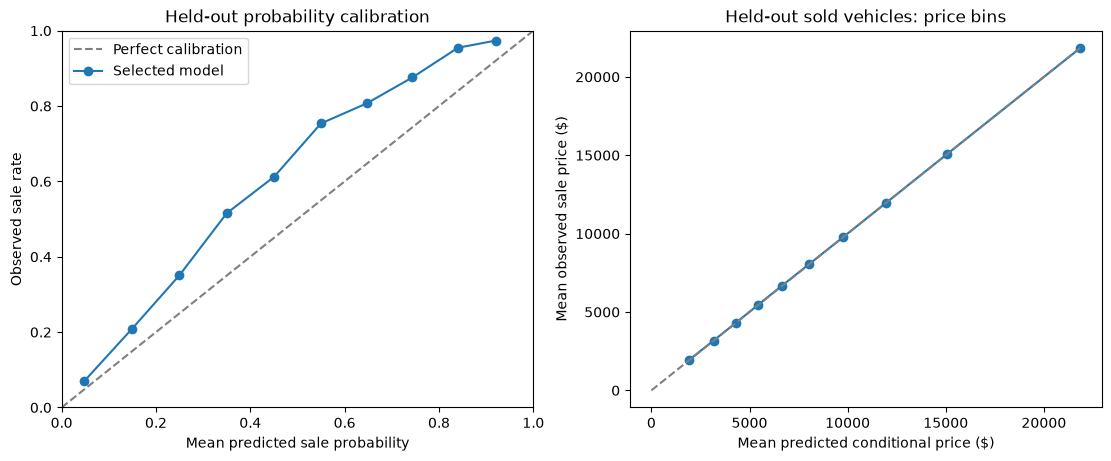

In [7]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
axes[0].plot([0,1],[0,1],color='gray',linestyle='--',label='Perfect calibration')
axes[0].plot(reliability.predicted,reliability.observed,'o-',label='Selected model')
axes[0].set(xlabel='Mean predicted sale probability',ylabel='Observed sale rate',title='Held-out probability calibration',xlim=(0,1),ylim=(0,1))
axes[0].legend()
price_bins=pd.DataFrame({'predicted':p[sold],'observed':actual_price})
price_bins['bin']=pd.qcut(price_bins.predicted,10,duplicates='drop')
means=price_bins.groupby('bin',observed=True)[['predicted','observed']].mean()
axes[1].plot(means.predicted,means.observed,'o-')
limit=max(means.max());axes[1].plot([0,limit],[0,limit],'--',color='gray')
axes[1].set(xlabel='Mean predicted conditional price ($)',ylabel='Mean observed sale price ($)',title='Held-out sold vehicles: price bins')
fig.savefig(OUT/'test_diagnostics.png',dpi=180)
plt.show()


## 7. Save selected models and verify artifacts

The cloudpickle bundle contains the selected fitted estimators, feature function, spline implementation, smearing rules, and calendar origin for trusted local reuse. Load only project-generated model files. Candidate selection does not refit on the test period. Model performance is from one development dataset, not the 30-replication policy experiment promised for the final study.


In [8]:
# Verify spline implementation has linear tails and creates one linear plus K-2 nonlinear terms.
spline=RestrictedCubicSpline().fit(np.linspace(.5,2,100)[:,None])
assert spline.transform(np.array([[.5],[1.0]])).shape==(2,3)
for points in [np.array([.1,.2,.3]),np.array([3.,4.,5.])]:
    basis=spline.transform(points[:,None])
    assert np.allclose(basis[0]-2*basis[1]+basis[2],0,atol=1e-10)
assert np.isfinite(q).all() and ((q>=0)&(q<=1)).all()
assert np.isfinite(p).all() and (p+1e-8>=test.floor.to_numpy()).all()
assert set(parts['train'].vehicle_id).isdisjoint(parts['test'].vehicle_id)
bundle=dict(classifier=classifier,price_model=price_model,features=features,price_predict=price_predict,
            feature_columns=FEATURES,origin=origin,floor_edges=floor_edges,
            classifier_name=classifier_name,price_name=price_name)
with (OUT/'selected_models.pkl').open('wb') as f: cloudpickle.dump(bundle,f)
with (OUT/'selected_models.pkl').open('rb') as f: restored=cloudpickle.load(f)
probe=test.head(30);probe_x=restored['features'](probe)
assert np.allclose(restored['classifier'].predict_proba(probe_x)[:,1],q[:30])
assert np.allclose(restored['price_predict'](restored['price_model'],probe_x)[0],p[:30])
metadata=dict(input=str(INPUT),input_sha256=input_hash,seed=SEED,features=FEATURES,
              split_summary=split_rows,selected_classifier=classifier_name,selected_price=price_name,
              smearing_mode=price_model['mode'],smearing_stability_tolerance=SMEARING_STABILITY_TOLERANCE,
              category_min_count=MIN_CATEGORY_COUNT,price_floor_adjustments=int(adjusted.sum()),
              elapsed_seconds=time.perf_counter()-started,python=platform.python_version(),
              packages={p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','matplotlib','cloudpickle']},
              scope='Single development simulation; no policy evaluation or empirical causal claims')
(OUT/'training_metadata.json').write_text(json.dumps(metadata,indent=2)+'\n')
assert json.loads((OUT/'training_metadata.json').read_text())['input_sha256']==input_hash
with INPUT.open('rb') as f: assert hashlib.file_digest(f,'sha256').hexdigest()==input_hash
print('Verified: date separation, feature restrictions, spline tails, prediction validity, model serialization, unchanged input.')
print('Saved outputs:',OUT.resolve())


Verified: date separation, feature restrictions, spline tails, prediction validity, model serialization, unchanged input.
Saved outputs: /Users/ecilteodoro/Library/Mobile Documents/com~apple~CloudDocs/UWF/2026-8/IDC6940/idc6940-capstone-project/data/training/binding_historical


In [9]:
from IPython.display import Markdown
_n=split_summary.set_index('split').n
_sel=test_metrics.set_index('model').loc['selected']
display(Markdown(f"""## Interpretation of this development run

Validation selected `{classifier_name}` for conversion and `{price_name}` for conditional price. The {_n['train']:,} training, {_n['validation']:,} validation, and {_n['test']:,} test observations preserve complete dates.

The held-out sale model {'underpredicts' if q.mean()<actual_sale.mean() else 'overpredicts'} conversion: mean predicted probability is {q.mean():.1%}, compared with {actual_sale.mean():.1%} observed. Test ROC-AUC is {_sel.roc_auc:.3f} and Brier score is {_sel.brier:.3f}. Gross proceeds are {'underpredicted' if _sel.gross_bias<0 else 'overpredicted'} by approximately ${abs(_sel.gross_bias):,.0f} per offered vehicle. These results show a calibration limitation even though discrimination improves on the constant reference. No settings were changed in this notebook in response to the test results.

Conditional-price MAE is approximately ${_sel.price_mae:,.0f} and RMSE ${_sel.price_rmse:,.0f} among sales. This strong performance applies to the narrow price-premium distribution of the binding-floor generator, whose premiums were rescaled during source calibration. It does not establish comparable accuracy on real auction transactions.

Before relying on probability estimates in an optimizer, investigate calibration using development data and assess any revised procedure on new independent simulation replications. The current test period has already been inspected and must not be reused as an untouched test for later tuning. No floor policy is fitted or evaluated in this notebook."""))


## Interpretation of this development run

Validation selected `logistic_3knots_C1.0` for conversion and `boosted_leaves15` for conditional price. The 29,989 training, 9,992 validation, and 10,019 test observations preserve complete dates.

The held-out sale model underpredicts conversion: mean predicted probability is 39.0%, compared with 51.3% observed. Test ROC-AUC is 0.823 and Brier score is 0.189. Gross proceeds are underpredicted by approximately $1,177 per offered vehicle. These results show a calibration limitation even though discrimination improves on the constant reference. No settings were changed in this notebook in response to the test results.

Conditional-price MAE is approximately $78 and RMSE $114 among sales. This strong performance applies to the narrow price-premium distribution of the binding-floor generator, whose premiums were rescaled during source calibration. It does not establish comparable accuracy on real auction transactions.

Before relying on probability estimates in an optimizer, investigate calibration using development data and assess any revised procedure on new independent simulation replications. The current test period has already been inspected and must not be reused as an untouched test for later tuning. No floor policy is fitted or evaluated in this notebook.